# Cvičenie III - Viacrozmerné a stavové modely

## Viacrozmerné časové rady a ich analýza

Kým jednorozmerný časový rad sleduje vývoj jednej premennej, napríklad ceny akcie, viacrozmerný sleduje súčasne dve alebo viac premenných, ako napríklad ceny viacerých akcií, vývoj inflácie a úrokových sadzieb alebo vzťah medzi spotrebou a príjmom domácností.

Hlavnou myšlienkou viacrozmernej analýzy je, že vývoj jednej premennej môže súvisieť nielen s jej vlastnou minulosťou, ale aj s minulými hodnotami ostatných premenných.

### Setup and reproducibility

Use `numpy`, `pandas`, `matplotlib`, `scipy`, `statsmodels`, and `yfinance` in the notebook's Python environment. Run cells from top to bottom. Paths support both the workspace root and the notebook directory.

ETF data are **adjusted daily Close prices** (`auto_adjust=True`), accounting for splits and distributions. CSV snapshots in `data/` are reused when available; otherwise `yfinance` downloads them. The end argument is exclusive, so `2026-10-01` includes September 30. Trading holidays are not filled with invented prices. Downloaded adjusted history can be revised by the provider.

For forecasting, the last **three calendar months** are reserved for evaluation. ADF tests, lag selection, cointegration rank, and any scaling used to choose forecasting models use the preceding training sample only. Rolling forecasts use an expanding window and reveal each actual observation after predicting it.

In [1]:
from pathlib import Path
from inspect import signature
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import yfinance as yf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen, select_order as select_vecm_order

data_dir = Path('data')
if not (data_dir / 'energy.csv').is_file():
    data_dir = Path('03_exercises/data')
if not data_dir.is_dir():
    raise FileNotFoundError('Run from the workspace root or 03_exercises directory.')

print('Versions:', 'numpy', np.__version__, 'pandas', pd.__version__,
      'statsmodels', statsmodels.__version__, 'yfinance', yf.__version__)
adf_options = {'regression': 'c', 'autolag': 'AIC'}
if 'result_object' in signature(adfuller).parameters:
    adf_options['result_object'] = False


def validate_panel(frame, positive=False):
    frame = frame.copy().sort_index().astype(float)
    if not isinstance(frame.index, pd.DatetimeIndex):
        raise ValueError('Expected a DatetimeIndex.')
    if frame.index.hasnans or not frame.index.is_unique or frame.empty:
        raise ValueError('Dates must be nonmissing and unique; the panel cannot be empty.')
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError('Handle missing or nonfinite values explicitly before modelling.')
    if positive and (frame <= 0).any().any():
        raise ValueError('Adjusted prices must be positive for log returns.')
    return frame


def load_etf_prices(symbols, start, end_inclusive, filename):
    file = data_dir / filename
    if file.is_file():
        close = pd.read_csv(file, index_col='Date', parse_dates=['Date'])
        origin = f'CSV snapshot: {file.name}'
    else:
        # Configure the provider cache locally rather than writing to user settings.
        yf.set_tz_cache_location(str(data_dir / '.yfinance-cache'))
        end_exclusive = (pd.Timestamp(end_inclusive) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        raw = yf.download(symbols, start=start, end=end_exclusive,
                          auto_adjust=True, progress=False, threads=False, timeout=30)
        if raw is None or raw.empty:
            raise RuntimeError('ETF download failed. Check the connection or supply the CSV snapshot.')
        close = raw['Close'].reindex(columns=symbols)
        if close.isna().all().any():
            raise RuntimeError('At least one requested ETF has no downloaded prices.')
        complete = close.dropna(how='any')
        print(f'{filename}: removed {len(close) - len(complete)} incomplete shared trading dates; no filling.')
        close = complete.copy()
        close.index = pd.to_datetime(close.index).tz_localize(None)
        close.index.name = 'Date'
        close = validate_panel(close, positive=True)
        close.to_csv(file)
        origin = 'yfinance download; saved adjusted Close snapshot'
    missing = set(symbols) - set(close.columns)
    if missing:
        raise ValueError(f'Missing ETF columns: {missing}')
    close = validate_panel(close.loc[start:end_inclusive, symbols], positive=True)
    if (close.index.min() > pd.Timestamp(start) + pd.Timedelta(days=7)
            or close.index.max() < pd.Timestamp(end_inclusive) - pd.Timedelta(days=7)):
        raise ValueError('The price snapshot does not cover the requested period.')
    print(f'{origin}: {len(close)} observations, {close.index.min():%Y-%m-%d} to {close.index.max():%Y-%m-%d}')
    return close


def split_last_three_months(frame):
    cutoff = (frame.index.max().to_period('M') - 2).start_time
    training = frame.loc[frame.index < cutoff].copy()
    testing = frame.loc[frame.index >= cutoff].copy()
    if len(training) < 60 or testing.empty:
        raise ValueError('Not enough observations for training and a three-month holdout.')
    if training.index.max() >= testing.index.min():
        raise ValueError('Training and testing dates overlap.')
    return training, testing


def adf_table(frame, alpha=0.05):
    rows = []
    for column in frame:
        for transform, values in [('Level', frame[column]),
                                  ('First difference', frame[column].diff().dropna())]:
            stat, p_value, lag, n_obs, _, _ = adfuller(values, **adf_options)
            rows.append({'Variable': column, 'Transformation': transform,
                         'ADF statistic': stat, 'p-value': p_value,
                         'ADF lags': lag, 'Observations': n_obs,
                         'Reject unit root': p_value < alpha})
    return pd.DataFrame(rows).set_index(['Variable', 'Transformation'])


def johansen_table(frame, k_ar_diff=1):
    # Constant rescaling improves conditioning without changing integration order.
    scaled = frame / frame.std()
    if not np.isfinite(scaled.to_numpy()).all():
        raise ValueError('Every training variable needs positive finite variation.')
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        result = coint_johansen(scaled.to_numpy(), det_order=0, k_ar_diff=k_ar_diff)
    # Some numerical-library versions return real eigenvalues as complex + 0j.
    if np.max(np.abs(np.imag(result.eig))) > 1e-8:
        raise ValueError('Johansen eigenvalues have material imaginary components.')
    for item in caught:
        if item.category.__name__ != 'ComplexWarning':
            warnings.warn(str(item.message), item.category)
    return pd.DataFrame({
        'H0': [f'r <= {i}' for i in range(frame.shape[1])],
        'Trace statistic': result.lr1,
        'Critical (5%)': result.cvt[:, 1],
        'Critical (1%)': result.cvt[:, 2],
        'Reject (5%)': result.lr1 > result.cvt[:, 1],
        'Reject (1%)': result.lr1 > result.cvt[:, 2],
    })


def sequential_rank(table, alpha=0.05):
    key = 'Reject (5%)' if alpha == 0.05 else 'Reject (1%)'
    if alpha not in (0.05, 0.01):
        raise ValueError('This exercise reports the 5% and 1% critical values.')
    # Stop at the first non-rejected null, rather than counting all rejections.
    return next((i for i, reject in enumerate(table[key]) if not reject), len(table))


def model_recommendation(adf, rank, n_variables, alpha=0.05):
    level_p = adf.xs('Level', level='Transformation')['p-value']
    diff_p = adf.xs('First difference', level='Transformation')['p-value']
    if (level_p < alpha).all():
        return 'VAR in levels'
    all_i1_candidates = (level_p >= alpha).all() and (diff_p < alpha).all()
    if not all_i1_candidates:
        return 'Review mixed/unclear integration orders'
    if rank == 0:
        return 'VAR in first differences'
    if rank < n_variables:
        return 'VECM'
    return 'Full rank: VAR levels candidate; review ADF conflict'


def forecast_scores(actual, predicted):
    if not actual.index.equals(predicted.index) or not actual.columns.equals(predicted.columns):
        raise ValueError('Forecast dates and variables must match actual observations.')
    if not np.isfinite(predicted.to_numpy()).all():
        raise ValueError('Forecasts must be finite.')
    error = predicted - actual
    return pd.DataFrame({'MAE': error.abs().mean(),
                         'RMSE': np.sqrt(error.pow(2).mean())}).rename_axis('Variable')


def plot_predictions(actual, predicted, title):
    fig, axes = plt.subplots(len(actual.columns), 1, figsize=(13, 3 * len(actual.columns)),
                             sharex=True, squeeze=False)
    for ax, column in zip(axes[:, 0], actual.columns):
        ax.plot(actual.index, actual[column], color='black', label='Actual')
        ax.plot(predicted.index, predicted[column], color='tab:orange',
                linestyle='--', label='One-step forecast')
        ax.set_ylabel(column)
        ax.grid(alpha=0.3)
        ax.legend()
    axes[-1, 0].set_xlabel('Forecast date')
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

Versions: numpy 2.5.3 pandas 3.1.0 statsmodels 0.15.0 yfinance 1.7.0


----------
### CCF

Pri analýze viacrozmerných časových radov nás zaujíma nielen vývoj jednotlivých premenných, ale aj ich vzájomné vzťahy v čase. Jedným zo spôsobov, ako tieto vzťahy skúmať je krížová korelačná funkcia (CCF).

Funkcia umožňuje skúmať lineárnu závislosť medzi dvoma časovými radmi pri rôznych časových lagoch. Postupne porovnávame hodnoty jednej premennej s časovo posunutými hodnotami druhej premennej a sledujeme, pri ktorých oneskoreniach je ich vzájomná korelácia najvýraznejšia.

$$
\rho_{XY}(h) = \operatorname{Corr}(X_t, Y_{t-h})
$$

Predpokladajme, že pozorujeme nasledujúce denné dáta:

| Deň | Reklama ($X$) | Tržby ($Y$) |
| :---: | :---: | :---: |
| **1** | 10 | 0 |
| **2** | 0 | 0 |
| **3** | 0 | 10 |
| **4** | 20 | 0 |
| **5** | 0 | 0 |
| **6** | 0 | 20 |
| **7** | 15 | 0 |
| **8** | 0 | 0 |
| **9** | 0 | 15 |

* Reklama v čase $t$ sa prejaví na tržbách presne o **2 dni neskôr** ($t+2$).



CSV snapshot: etf_ccf_2025-01-01_2026-09-30.csv: 437 observations, 2025-01-02 to 2026-09-30


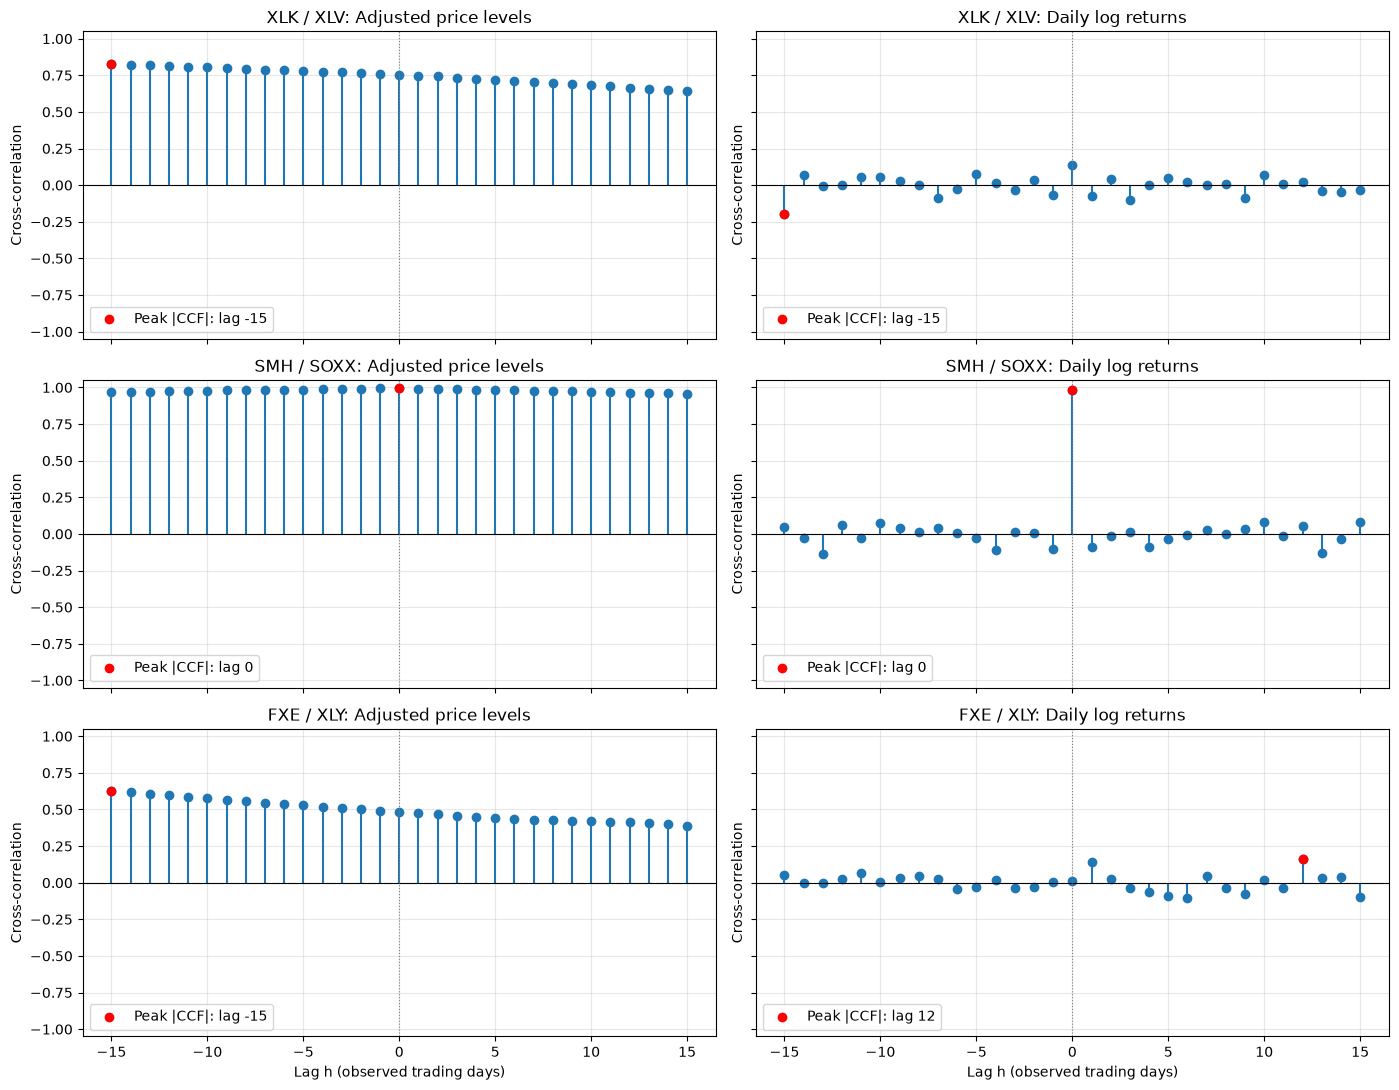

                                  Peak lag  CCF at peak  CCF at lag 0
Pair       Input                                                     
XLK / XLV  Adjusted price levels       -15      0.82547       0.75527
           Daily log returns           -15     -0.19705       0.13620
SMH / SOXX Adjusted price levels         0      0.99593       0.99593
           Daily log returns             0      0.98302       0.98302
FXE / XLY  Adjusted price levels       -15      0.62776       0.48527
           Daily log returns            12      0.16154       0.01133


In [2]:
# TODO:
# 1. Pomocou knižnice yfinance načítajte denné ceny ETF pre XLK, XLV, SMH, SOXX, FXE, XLY
#    za obdobie od 1. 1. 2025 do 30. 9. 2026.
##
# 3. Vypočítajte a zobrazte CCF pre lagy od -15 do +15 pre tieto dvojice:
#    - XLK a XLV
#    - SMH a SOXX
#    - FXE a XLY
# Záporné aj kladné lagy zobrazte
#    v jednom grafe.
#
# 4. Pre každú dvojicu identifikujte lag, pri ktorom
#    absolútna hodnota CCF dosahuje maximum.
#    Pri hľadaní maxima nezabudnite zahrnúť aj lag 0.
#
# 5. Vysvetlite, prečo samotná krížová korelácia
#    nedokazuje kauzálny vzťah medzi premennými.

ccf_prices = load_etf_prices(
    ['XLK', 'XLV', 'SMH', 'SOXX', 'FXE', 'XLY'], '2025-01-01', '2026-09-30',
    'etf_ccf_2025-01-01_2026-09-30.csv',
)
ccf_returns = np.log(ccf_prices).diff().dropna()
ccf_pairs = [('XLK', 'XLV'), ('SMH', 'SOXX'), ('FXE', 'XLY')]
ccf_lags = np.arange(-15, 16)
ccf_rows = []
fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True, sharey=True)
for row, (x_name, y_name) in enumerate(ccf_pairs):
    for column, (label, frame) in enumerate([
        ('Adjusted price levels', ccf_prices), ('Daily log returns', ccf_returns)
    ]):
        # rho_XY(h) = Corr(X_t, Y_(t-h)); shift aligns by observed trading day.
        correlations = pd.Series({
            int(h): frame[x_name].corr(frame[y_name].shift(int(h))) for h in ccf_lags
        }, name='CCF')
        best_lag = int(correlations.abs().idxmax())  # includes zero
        peak = float(correlations.loc[best_lag])
        ccf_rows.append({'Pair': f'{x_name} / {y_name}', 'Input': label,
                         'Peak lag': best_lag, 'CCF at peak': peak,
                         'CCF at lag 0': correlations.loc[0]})
        ax = axes[row, column]
        ax.stem(correlations.index, correlations.values, basefmt=' ')
        ax.scatter(best_lag, peak, color='red', zorder=4, label=f'Peak |CCF|: lag {best_lag}')
        ax.axhline(0, color='black', linewidth=0.8)
        ax.axvline(0, color='gray', linestyle=':', linewidth=0.8)
        ax.set_title(f'{x_name} / {y_name}: {label}')
        ax.set_ylim(-1.05, 1.05)
        ax.set_xticks(range(-15, 16, 5))
        ax.set_ylabel('Cross-correlation')
        ax.grid(alpha=0.3)
        ax.legend(loc='lower left')
for ax in axes[-1]:
    ax.set_xlabel('Lag h (observed trading days)')
fig.tight_layout()
plt.show()
ccf_maxima = pd.DataFrame(ccf_rows).set_index(['Pair', 'Input'])
print(ccf_maxima.to_string(float_format=lambda value: f'{value:.5f}'))


### Exercise 1 — interpretation

- Each plot contains negative, zero, and positive lags. The table reports the signed correlation at the largest **absolute** correlation; lag zero participates in the search.
- With the displayed convention `Corr(X_t, Y_(t-h))`, **positive h means Y precedes X**, and negative h means X precedes Y. At zero, the relationship is contemporaneous. A lag is one shared trading observation, not necessarily one calendar day.
- Price-level CCF answers the literal price comparison. Trending levels can create large correlations across many lags. Log-return CCF is a complementary comparison of daily relative changes and reduces this particular source of spurious association. It does not automatically remove all serial dependence.
- Compare XLK/XLV (different sectors), SMH/SOXX (overlapping semiconductor exposure), and FXE/XLY (currency versus consumer sector) using the computed table, rather than assuming a particular peak in advance. High contemporaneous correlation is plausible for overlapping funds, but must be checked in these data.
- Correlation does not establish causation: common market shocks, overlapping holdings, autocorrelation, and omitted variables can explain the relationship. Selecting a maximum across 31 lags is exploratory and does not supply a corrected significance test or establish forecast usefulness.

**Results for the saved snapshots:** SMH/SOXX peaks at lag 0 for both levels (0.99593) and log returns (0.98302), showing strong contemporaneous association. For returns, XLK/XLV peaks at lag -15 (-0.19705), and FXE/XLY at lag +12 (0.16154). These much smaller exploratory peaks do not establish reliable lead/lag prediction. Several level maxima occur at the search boundary (-15), so they do not identify an interior peak or a well-established delay.

-------
### Kointegrácia

Pri analýze časových radov mnohé premenné vykazujú v čase trend, čo znamená, že sú nestacionárne. Táto nestacionarita môže predstavovať problém pri tvorbe štatistických modelov, pretože môže viesť k zavádzajúcim výsledkom. Niekedy sa však dva alebo viaceré nestacionárne časové rady vyvíjajú spoločne takým spôsobom, že ich kombinácia je stacionárna. Tento vzťah nazývame kointegrácia.


Johansenov test slúži na overenie existencie dlhodobých vzťahov medzi viacerými nestacionárnymi časovými radmi, ktoré sú integrované rádu $I(1)$. Test určuje počet nezávislých kointegračných vzťahov, tzv. kointegračný rank $r$.


Pri troch časových radoch testujeme postupne tieto hypotézy:
| Nulová hypotéza $H_0$ |
|---|
| $r = 0$ | 
| $r \leq 1$ | 
| $r \leq 2$ |

- $r = 0$: neidentifikovali sme žiadny kointegračný vzťah.
- $r = 1$: existuje jeden kointegračný vzťah.
- $r = 2$: existujú dva nezávislé kointegračné vzťahy.
- $r = 3$: plný rank.

Pri testovaní používame pôvodné cenové úrovne alebo ich logaritmy, nie prvé diferencie a kointegračný rank určujeme podľa prvej nezamietnutej hypotézy.

| Situácia | Model 
| :--- | :--- |
| Rady sú stacionárne, $I(0)$ | **VAR v úrovniach** *(VAR in levels)* |
| Rady sú nestacionárne, $I(1)$, a **nie sú** kointegrované | **VAR v prvých diferenciách** *(VAR in differences)* | 
| Rady sú nestacionárne, $I(1)$, a **sú** kointegrované | **VECM** *(Vector Error Correction Model)* |


CSV snapshot: etf_models_2020-01-01_2026-09-30.csv: 1695 observations, 2020-01-02 to 2026-09-30
Train: 1631 dates, 2020-01-02 to 2026-06-30
Test: 64 dates, 2026-07-01 to 2026-09-30

SPY / IVV / VOO: training data only
                           ADF statistic     p-value  ADF lags  Observations  Reject unit root
Variable Transformation                                                                       
SPY      Level                  0.498305    0.984821         9          1621             False
         First difference       -13.4669 3.44188e-25         8          1621              True
IVV      Level                  0.487083    0.984475         9          1621             False
         First difference       -13.4219 4.17364e-25         8          1621              True
VOO      Level                  0.503365    0.984975         9          1621             False
         First difference       -13.3898 4.79297e-25         8          1621              True
Johansen trace: det_or

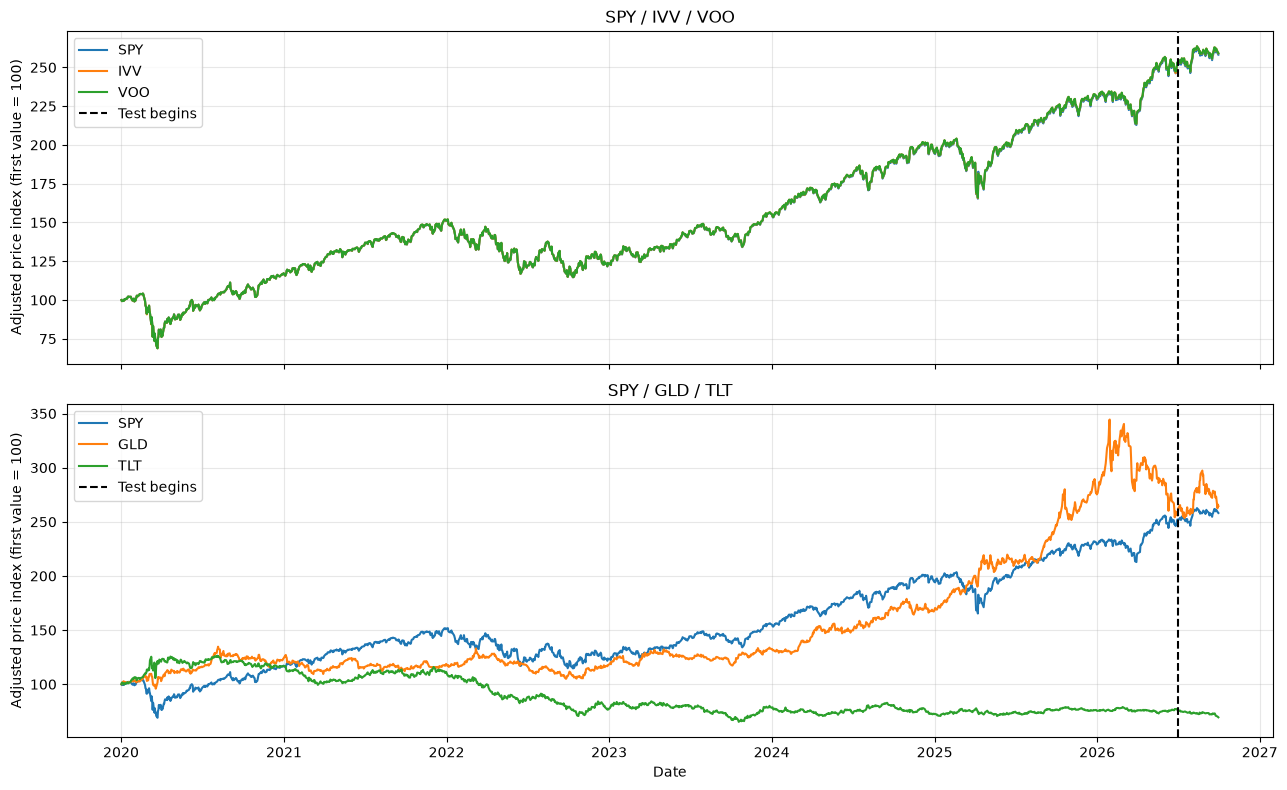

In [3]:
# TODO:
# 1. Pomocou yfinance načítajte denné ceny ETF
#    za obdobie od 1. 1. 2020 do 30. 9. 2026 pre tieto trojice:
#    -  SPY, IVV, VOO
#    -  SPY, GLD, TLT
#
# 2. Pomocou ADF testu overte stacionaritu jednotlivých
#    časových radov.
#
# 3. Na pôvodné cenové úrovne aplikujte Johansenov
#    kointegračný test.
#    Použite det_order=0 a k_ar_diff=1.
#
# 4. Určte kointegračný rank r pre každú skupinu.
#
# 5. Na základe ADF a Johansenovho testu rozhodnite,
#    či je pre danú skupinu vhodnejší VAR
#    na prvých diferenciách alebo VECM.

etf_prices = load_etf_prices(
    ['SPY', 'IVV', 'VOO', 'GLD', 'TLT'], '2020-01-01', '2026-09-30',
    'etf_models_2020-01-01_2026-09-30.csv',
)
etf_train, etf_test = split_last_three_months(etf_prices)
print(f'Train: {len(etf_train)} dates, {etf_train.index.min():%Y-%m-%d} to {etf_train.index.max():%Y-%m-%d}')
print(f'Test: {len(etf_test)} dates, {etf_test.index.min():%Y-%m-%d} to {etf_test.index.max():%Y-%m-%d}')
etf_groups = {'SPY / IVV / VOO': ['SPY', 'IVV', 'VOO'],
              'SPY / GLD / TLT': ['SPY', 'GLD', 'TLT']}
etf_analysis = {}
etf_decisions = []
for group_name, columns in etf_groups.items():
    group_train = etf_train[columns]
    adf = adf_table(group_train)
    trace = johansen_table(group_train, k_ar_diff=1)
    rank = sequential_rank(trace)
    recommendation = model_recommendation(adf, rank, len(columns))
    etf_analysis[group_name] = {'adf': adf, 'trace': trace, 'rank': rank,
                               'recommendation': recommendation}
    etf_decisions.append({'Group': group_name, 'Rank (5%)': rank,
                          'Variables': len(columns), 'Model': recommendation})
    print(f'\n{group_name}: training data only')
    print(adf.to_string(float_format=lambda value: f'{value:.6g}'))
    print('Johansen trace: det_order=0, k_ar_diff=1')
    print(trace.to_string(index=False, float_format=lambda value: f'{value:.6g}'))
print('\nModel decisions (alpha=0.05):')
etf_model_decisions = pd.DataFrame(etf_decisions).set_index('Group')
print(etf_model_decisions.to_string())

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, (group_name, columns) in zip(axes, etf_groups.items()):
    normalized = etf_prices[columns].div(etf_prices[columns].iloc[0]).mul(100)
    for column in columns:
        ax.plot(normalized.index, normalized[column], label=column)
    ax.axvline(etf_test.index.min(), color='black', linestyle='--', label='Test begins')
    ax.set_title(group_name)
    ax.set_ylabel('Adjusted price index (first value = 100)')
    ax.grid(alpha=0.3)
    ax.legend()
axes[-1].set_xlabel('Date')
fig.tight_layout()
plt.show()


### Exercise 2 — interpretation

- ADF is applied to both levels and first differences, using a constant and AIC-selected test lags. A level p-value at least 0.05 followed by a difference p-value below 0.05 is consistent with an I(1) series; failure to reject alone does not prove a unit root.
- Johansen is applied to the **price levels**, with the requested `det_order=0` and `k_ar_diff=1`. Rank is the first non-rejected trace-test null. `k_ar_diff=1` denotes one lag of differences, corresponding to a two-lag VAR representation in levels.
- Rank zero means no cointegrating relation is detected; rank r between zero and k indicates r independent stationary combinations and k-r common stochastic trends. Full rank requires reassessing the I(1) premise.
- The data-driven decision table determines VAR in differences versus VECM. Similar-looking or highly correlated price paths alone do not establish cointegration. The SPY/IVV/VOO group tracks a common market index, while SPY/GLD/TLT represents different asset classes; the actual test results decide their classification.
- The tests here use training data through June 2026, reserving July–September 2026. The full-history plots are descriptive only. Adjusted prices, deterministic terms, lag choices, and sample endpoints can change the result.

**Results for the saved snapshots:** SPY/IVV/VOO has rank **2**, supporting two equilibrium relations and one common stochastic trend: VECM is appropriate under these assumptions. SPY/GLD/TLT has rank **0**, supporting VAR in first differences. For every individual series, ADF fails to reject a unit root in levels and rejects it after one difference at 5%.

Training-only AIC search (lags 0 through 10):
          AIC
Lags         
0    5.897478
1    5.894047
2    5.876569
3    5.869678
4    5.870871
5    5.875101
6    5.876469
7    5.878340
8    5.872868
9    5.867803
10   5.871690
Selected VAR(9) in first differences; stable: True
Cointegration diagnostic: VAR in first differences

One-trading-day-ahead errors in adjusted USD prices:
                    MAE     RMSE
Model Variable                  
VAR   SPY      4.225717 5.337595
      GLD      4.841495 6.157715
      TLT      0.429882 0.553958
Naive SPY      4.094022 5.169949
      GLD      4.789690 6.059919
      TLT      0.395331 0.517476
Rolling origins: 64 ; all fits stable: True
              History end  Training observations  Stable
Forecast date                                           
2026-07-01     2026-06-30                   1630    True
2026-09-30     2026-09-29                   1693    True


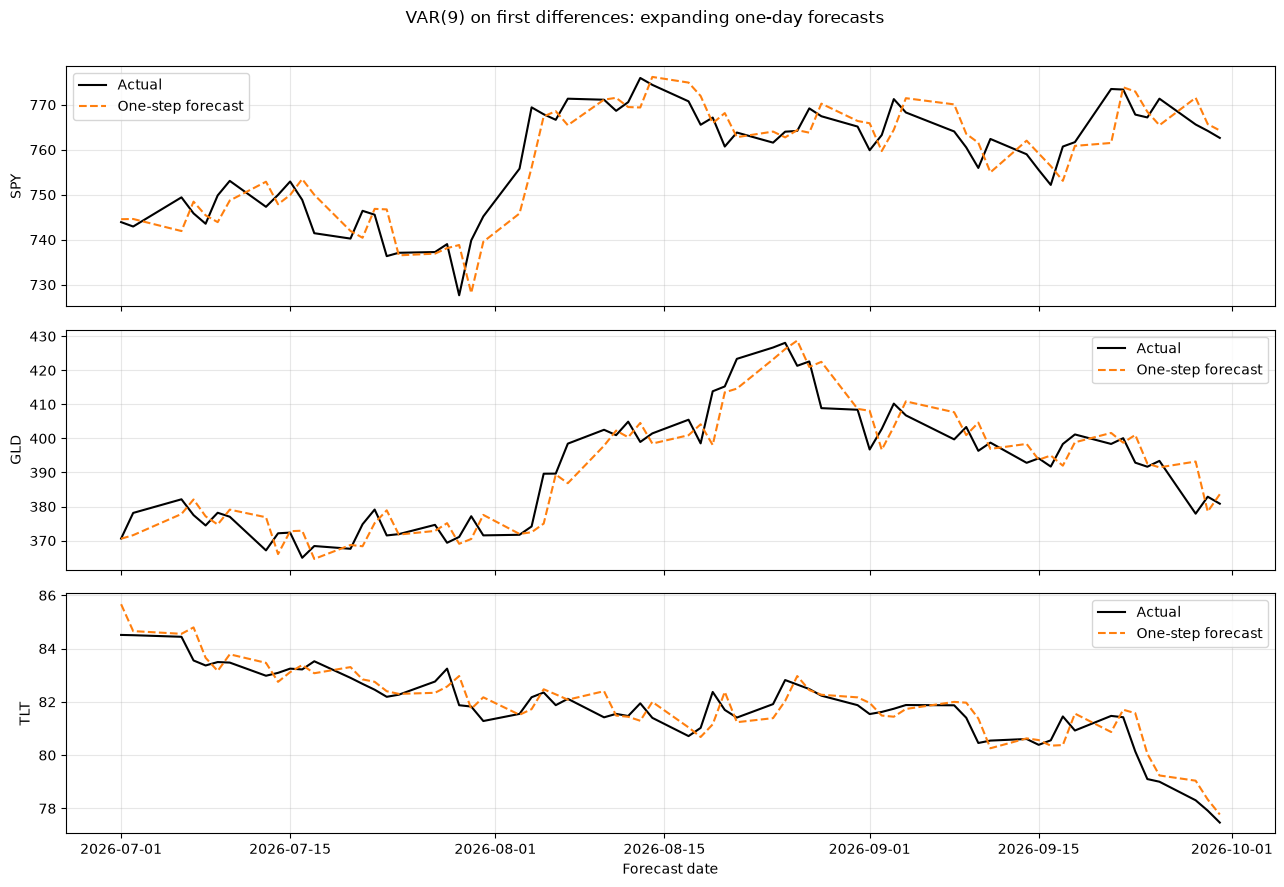

In [4]:
# TODO:
# 1. Rozdeľte dáta na trénovaciu množinu a testovaciu
#    množinu, ktorú tvoria posledné 3 mesiace.
#
# 2. Vytvorte VAR model pre SPY, GLD a TLT
#    na prvých diferenciách cien.
#
# 3. Pomocou AIC vyberte počet lagov
#    na trénovacích dátach - skúšajte od 0 do 10. 
#
# 4. Overte stabilitu modelu pomocou is_stable().
#
# 5. Vykonajte rolling-origin predikciu s horizontom 1 deň.
#
# 6. Predikované prvé diferencie preveďte späť
#     na pôvodné cenové úrovne.
#
# 7. Vykreslite skutočné a predikované ceny
#     ETF SPY, GLD a TLT počas testovacieho obdobia.
#
# 8. Vypočítajte RMSE predikcie pre každé ETF.

var_columns = ['SPY', 'GLD', 'TLT']
var_train = etf_train[var_columns].copy()
var_test = etf_test[var_columns].copy()
var_train_diff = var_train.diff().dropna()
# Preserve variable names without imposing an artificial daily/holiday frequency.
var_training_model = VAR(var_train_diff.reset_index(drop=True))
var_lag_selection = var_training_model.select_order(maxlags=10, trend='c')
var_aic_table = pd.DataFrame({'Lags': range(len(var_lag_selection.ics['aic'])),
                              'AIC': var_lag_selection.ics['aic']}).set_index('Lags')
var_lags = int(var_lag_selection.aic)
var_fit = var_training_model.fit(var_lags, trend='c')
var_stable = bool(var_fit.is_stable()) if var_lags else True
print('Training-only AIC search (lags 0 through 10):')
print(var_aic_table.to_string(float_format=lambda value: f'{value:.6f}'))
print(f'Selected VAR({var_lags}) in first differences; stable: {var_stable}')
print('Cointegration diagnostic:', etf_analysis['SPY / GLD / TLT']['recommendation'])
if etf_analysis['SPY / GLD / TLT']['rank'] != 0:
    print('Caution: the prescribed differenced VAR omits a detected level relationship.')
if not var_stable:
    print('Caution: the selected training model is unstable; do not interpret its IRF as decaying.')

var_history = var_train.copy()
var_forecast_rows, var_audit_rows = [], []
for forecast_date, actual_row in var_test.iterrows():
    if var_history.index.max() >= forecast_date:
        raise ValueError('The history contains the forecast target or future data.')
    history_diff = var_history.diff().dropna()
    fitted = VAR(history_diff.reset_index(drop=True)).fit(var_lags, trend='c')
    if var_lags:
        predicted_diff = fitted.forecast(history_diff.to_numpy()[-var_lags:], steps=1)[0]
        stable = bool(fitted.is_stable())
    else:
        # VAR(0) is a constant mean change: forecast() needs special handling.
        predicted_diff = np.asarray(fitted.intercept)
        stable = True
    last_observed = var_history.iloc[-1].to_numpy()
    predicted_level = last_observed + predicted_diff
    var_forecast_rows.append(predicted_level)
    var_audit_rows.append({'Forecast date': forecast_date,
                           'History end': var_history.index.max(),
                           'Training observations': len(history_diff), 'Stable': stable})
    # Reveal today's prices only after recording every predicted component.
    var_history.loc[forecast_date] = actual_row

var_predictions = pd.DataFrame(var_forecast_rows, index=var_test.index, columns=var_columns)
var_origins = pd.DataFrame(var_audit_rows).set_index('Forecast date')
var_scores = forecast_scores(var_test, var_predictions)
var_naive_predictions = etf_prices[var_columns].shift(1).loc[var_test.index]
var_naive_scores = forecast_scores(var_test, var_naive_predictions)
print('\nOne-trading-day-ahead errors in adjusted USD prices:')
print(pd.concat({'VAR': var_scores, 'Naive': var_naive_scores}, names=['Model']).to_string(
    float_format=lambda value: f'{value:.6f}'))
print('Rolling origins:', len(var_origins), '; all fits stable:', bool(var_origins['Stable'].all()))
print(var_origins.iloc[[0, -1]].to_string())
plot_predictions(var_test, var_predictions,
                 f'VAR({var_lags}) on first differences: expanding one-day forecasts')


### Exercise 3 — interpretation

- The test period is the last three calendar months. AIC compares all lag counts from 0 to 10 on **training differences**. The selected order is fixed before rolling evaluation, while coefficients are refitted at every origin.
- Each forecast is converted to prices using `predicted_price[t] = observed_price[t-1] + predicted_difference[t]`. A one-step forecast uses the most recently observed price, so it does not accumulate previous forecast errors as a fixed-origin multistep forecast would.
- The history expands after the actual observation is revealed. `var_origins` audits the information cutoff and stability at each origin. A VAR(0), if selected, predicts the constant mean difference and has no lag dynamics.
- `is_stable()` checks the fitted differenced VAR's dynamics, not whether the price levels themselves are stationary. Stability does not guarantee good forecast accuracy.
- MAE and RMSE are computed separately for each ETF on the original adjusted-price scale and identical dates. Naive predicts the last observed price and provides a useful benchmark. The plots can appear close even when errors are material; use the numerical scores rather than visual overlap alone.

**Reference results:** AIC selects **VAR(9)**; all 64 rolling fits are stable. On July–September 2026, Naive has lower MAE and RMSE for all three ETFs:

| ETF | VAR MAE | VAR RMSE | Naive MAE | Naive RMSE |
| --- | ---: | ---: | ---: | ---: |
| SPY | 4.225717 | 5.337595 | 4.094022 | 5.169949 |
| GLD | 4.841495 | 6.157715 | 4.789690 | 6.059919 |
| TLT | 0.429882 | 0.553958 | 0.395331 | 0.517476 |

These errors are adjusted USD price units. More complex cross-variable dynamics did not improve this holdout evaluation.

--------
### IRF

IRF ukazuje, ako systém reaguje na jednorazový šok v jednej premennej a ako sa tento účinok vyvíja v nasledujúcich obdobiach.

1. Znamienko odozvy: kladná hodnota znamená pozitívnu reakciu, záporná negatívnu.
2. Veľkosť odozvy: ako výrazne sa daná premenná zmení po šoku.
3. Trvanie odozvy: po koľkých obdobiach účinok približne zaniká.
4. Intervaly spoľahlivosti: či je nulová odozva zlučiteľná s odhadnutou neistotou.

    - Stĺpce predstavujú premennú, v ktorej nastal šok. 
    - Riadky predstavujú premennú, ktorej reakciu sledujeme.
    - Modrá čiara je odhadnutá impulzná odozva.
    - Čierne prerušované čiary predstavujú intervaly neistoty.

Parameter orth=True zabezpečuje výpočet ortogonalizovaných impulzných odoziev pomocou Choleského rozkladu, čím zobrazuje nekorelované šoky jednotlivých premenných. Orth=False zobrazuje korelované šoky.


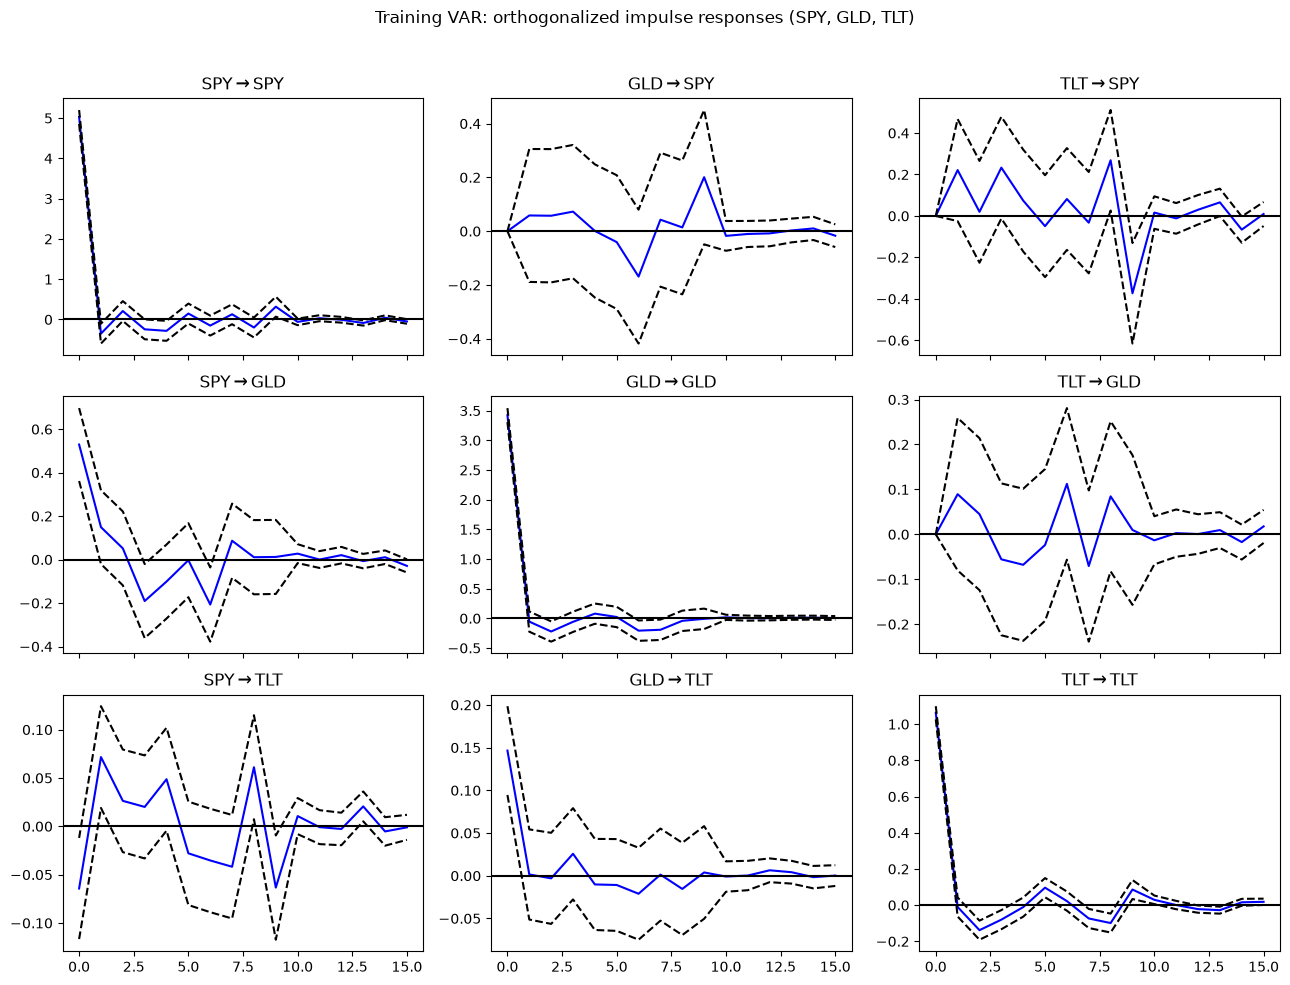

                 Impact (day 0)  Signed peak  Peak day  Day 15 response  Below 10% of peak from day 95% band excludes zero on days
Response to SPY                                                                                                                   
GLD                    0.529259     0.529259         0       -0.0290525                           8                      [0, 3, 6]
TLT                  -0.0643083    0.0716374         1      -0.00104828                          14               [0, 1, 8, 9, 13]
Responses are in daily USD price differences per one orthogonalized standard-deviation shock.


In [5]:
# TODO: 
# 1. Použite odhadnutý VAR model pre prvé diferencie cien
#    ETF SPY, GLD a TLT.
# 2. Vypočítajte impulzné odozvy pre horizont
#    15 obchodných dní.
# 3. Vykreslite ortogonalizované impulzné odozvy
#    pomocou funkcie irf.plot().
# 4. Preskúmajte, ako reagujú GLD a TLT na šok v SPY.
# 5. Určte znamienko, veľkosť a trvanie jednotlivých odoziev.
# 6. Posúďte, či sa odozvy postupne približujú k nule.

irf_horizon = 15
if var_lags:
    # Use the original training fit, not the final rolling fit containing test data.
    var_irf = var_fit.irf(irf_horizon)
    irf_figure = var_irf.plot(orth=True, signif=0.05, stderr_type='asym', figsize=(13, 10))
    irf_figure.suptitle('Training VAR: orthogonalized impulse responses (SPY, GLD, TLT)')
    irf_figure.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    irf_responses = var_irf.orth_irfs
    irf_standard_errors = var_irf.stderr(orth=True)
    irf_lower = irf_responses - 1.95996398454 * irf_standard_errors
    irf_upper = irf_responses + 1.95996398454 * irf_standard_errors
else:
    # A zero-lag VAR has a contemporaneous shock but no subsequent propagation.
    irf_responses = np.zeros((irf_horizon + 1, len(var_columns), len(var_columns)))
    irf_responses[0] = np.linalg.cholesky(np.asarray(var_fit.sigma_u))
    irf_lower = irf_upper = None
    fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
    for response in range(3):
        for impulse in range(3):
            axes[response, impulse].plot(range(irf_horizon + 1), irf_responses[:, response, impulse])
            axes[response, impulse].axhline(0, color='black', linewidth=0.7)
            axes[response, impulse].set_title(f'{var_columns[impulse]} → {var_columns[response]}')
    fig.suptitle('VAR(0): contemporaneous Cholesky effects; no lag propagation')
    fig.tight_layout()
    plt.show()
    print('VAR(0): irf.plot() has no lag dynamics to analyze; no uncertainty bands are claimed.')

irf_summary_rows = []
spy_impulse = var_columns.index('SPY')
for response_name in ['GLD', 'TLT']:
    response_index = var_columns.index(response_name)
    values = irf_responses[:, response_index, spy_impulse]
    peak_day = int(np.abs(values).argmax())
    peak_size = float(values[peak_day])
    threshold = 0.1 * abs(peak_size)
    settling_day = next((h for h in range(peak_day + 1, len(values))
                         if np.all(np.abs(values[h:]) <= threshold)), None)
    significant_days = [] if irf_lower is None else [
        h for h in range(len(values))
        if irf_lower[h, response_index, spy_impulse] > 0
        or irf_upper[h, response_index, spy_impulse] < 0
    ]
    irf_summary_rows.append({
        'Response to SPY': response_name,
        'Impact (day 0)': values[0], 'Signed peak': peak_size, 'Peak day': peak_day,
        'Day 15 response': values[-1],
        'Below 10% of peak from day': settling_day if settling_day is not None else 'Not within 15 days',
        '95% band excludes zero on days': str(significant_days) if irf_lower is not None else 'Not computed',
    })
irf_summary = pd.DataFrame(irf_summary_rows).set_index('Response to SPY')
print(irf_summary.to_string(float_format=lambda value: f'{value:.6g}'))
print('Responses are in daily USD price differences per one orthogonalized standard-deviation shock.')


### Exercise 4 — interpretation

- Columns are shock variables and rows are responding variables. The Cholesky ordering is **SPY, GLD, TLT**. These are orthogonalized one-standard-deviation innovations, so ordering affects the contemporaneous identification and the resulting responses.
- The summary table gives GLD's and TLT's impact response, signed largest absolute response, peak day, and response at day 15. Read the sign from the computed value; neither a positive nor negative response is assumed in advance.
- The reported settling time is a descriptive rule: from that day through day 15, every absolute response is at most 10% of its own peak. It is not a statistical significance test or proof of permanent disappearance. A stable model's responses should decay eventually, but may not do so within this short plotted horizon.
- For positive lag order, asymptotic 95% pointwise bands quantify uncertainty under the fitted VAR assumptions. An interval containing zero does not provide evidence of a nonzero response at that horizon; checking many horizons does not constitute one joint test.
- The VAR models **first price differences**. Its IRF describes changes in daily price changes, not the direct path of price levels; cumulative responses would address level effects. Cholesky orthogonalization alone does not establish economic causation.

**Reference results:** GLD initially responds positively (+0.5293 adjusted USD); its response subsequently changes sign and remains within 10% of its peak from day 8 through day 15. TLT initially responds negatively (-0.06431), has its largest absolute response on day 1 (+0.07164), and meets the same settling rule from day 14. Day-15 responses are about -0.02905 and -0.00105 respectively. Both approach zero within the plotted horizon under this descriptive rule; uncertainty and the dependence on Cholesky ordering still apply.

--------
## Stavové modely

Stavové modely (State-Space Models) slúžia na modelovanie časových radov, pri ktorých predpokladáme existenciu skrytého (nepozorovateľného) stavu systému.

Pozorované hodnoty obsahujú informáciu o tomto stave, ale môžu byť ovplyvnené náhodným šumom.


### Matematický zápis stavového modelu

**1. Stavová rovnica – ako sa vyvíja skrytý stav:**

$$
x_t = Fx_{t-1} + w_t
$$

**2. Pozorovacia rovnica – čo v skutočnosti pozorujeme:**

$$
y_t = Hx_t + v_t
$$

kde:

- $x_t$ – skrytý (nepozorovateľný) stav systému,
- $y_t$ – pozorovaná hodnota časového radu,
- $F$ – určuje, ako aktuálny stav závisí od predchádzajúceho stavu,
- $H$ – určuje vzťah medzi skrytým stavom a pozorovaním,
- $w_t$ – stavový šum, teda náhodné zmeny samotného systému,
- $v_t$ – pozorovací šum, teda náhodná chyba merania.

Predpokladáme, že šumy majú nulovú strednú hodnotu, sú nezávislé a majú normálne rozdelenie:

$$
w_t \sim N(0,Q), \qquad v_t \sim N(0,R)
$$

Parametre $Q$ a $R$ predstavujú rozptyly jednotlivých šumov.

### AR(1) ako stavový model

Z predchádzajúcich cvičení poznáme autoregresný model prvého rádu:

$$
x_t = \phi x_{t-1} + w_t
$$

Ak tento proces nepozorujeme priamo, ale iba s náhodnou chybou, môžeme ho zapísať ako stavový model:

**Stavová rovnica:**

$$
x_t = \phi x_{t-1} + w_t
$$

**Pozorovacia rovnica:**

$$
y_t = x_t + v_t
$$

V porovnaní so všeobecným stavovým modelom platí:

$$
F = \phi, \qquad H = 1
$$

### Simulácia AR(1) stavového modelu

Použijeme nasledujúce parametre:

| Parameter |  Význam |
|---|---
| $n$ | Počet simulovaných časových okamihov |
| $\phi$ | Sila závislosti skrytého stavu od jeho minulosti |
| $Q$ | Rozptyl stavového šumu |
| $R$ | Rozptyl pozorovacieho šumu |

**3. Rozdiel medzi $Q$ a $R$**

- Väčšie $Q$ znamená väčšie náhodné zmeny **skutočného skrytého stavu**.
- Väčšie $R$ znamená väčšiu chybu **pozorovaných hodnôt**.

V reálnej situácii však spravidla poznáme iba pozorovania a skrytý stav nevieme priamo určiť.


In [6]:
# Stavová rovnica:       x_t = phi * x_(t-1) + w_t
# Pozorovacia rovnica:   y_t = x_t + v_t
#
# state        = skrytý stav systému
# observations = zašumené pozorovania

import numpy as np
import matplotlib.pyplot as plt

# 1. Parametre stavového modelu
rng = np.random.default_rng(42)

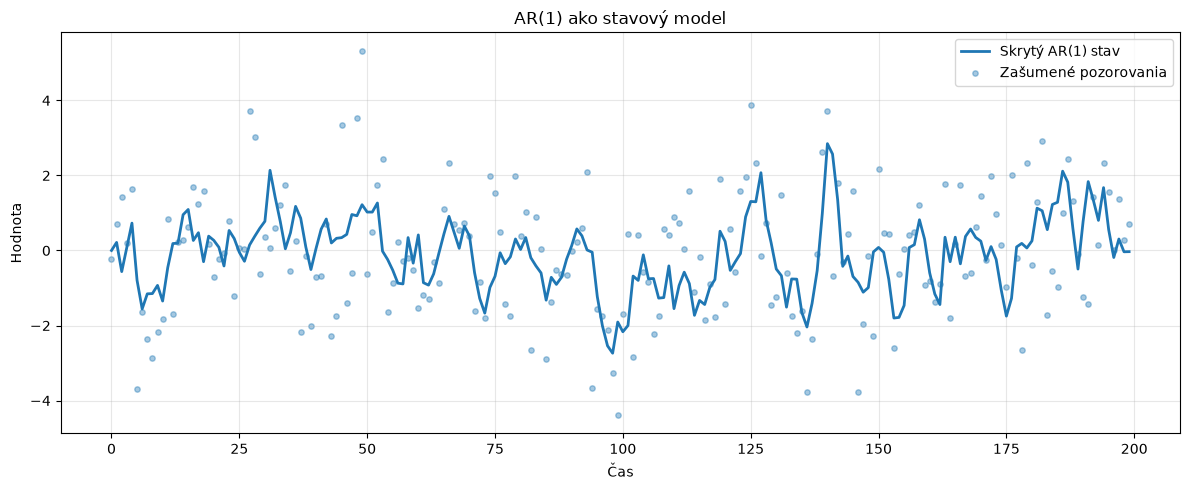

In [7]:
# 1. Parametre stavového modelu
n = 200
phi = 0.8
Q = 0.5
R = 2.0

# 2. Simulácia skrytého AR(1) stavu
rng = np.random.default_rng(42)  # Repeatable even when this cell is rerun.
state = np.zeros(n)

for t in range(1, n):
    w_t = rng.normal(0, np.sqrt(Q))
    # TODO: Vypočítajte aktuálnu hodnotu skrytého stavu podľa stavovej rovnice AR(1).
    state[t] = phi * state[t - 1] + w_t

# 3. Vytvorenie zašumených pozorovaní
v = rng.normal(0, np.sqrt(R), size=n)
observations = state + v

#4. Vizualizácia
plt.figure(figsize=(12, 5))

plt.plot(
    state,
    label="Skrytý AR(1) stav",
    linewidth=2
)

plt.scatter(
    range(n),
    observations,
    label="Zašumené pozorovania",
    alpha=0.4,
    s=15
)

plt.title("AR(1) ako stavový model")
plt.xlabel("Čas")
plt.ylabel("Hodnota")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# TODO 5: Experimentovanie s parametrami
#
# 1. Zmeňte phi z 0.8 na -0.8.
#    Ako sa zmení priebeh skrytého stavu?
#
# 2. Vráťte phi na 0.8 a zvýšte Q z 0.5 na 2.0.
#    Ako sa zmenia náhodné výkyvy skrytého stavu?
#
# 3. Vráťte Q na 0.5 a zvýšte R z 2.0 na 5.0.
#    Ako sa zmení rozdiel medzi skrytým stavom a pozorovaniami?
#
# Pri každom experimente meňte iba jeden parameter.
# Ostatné parametre ponechajte nezmenené.


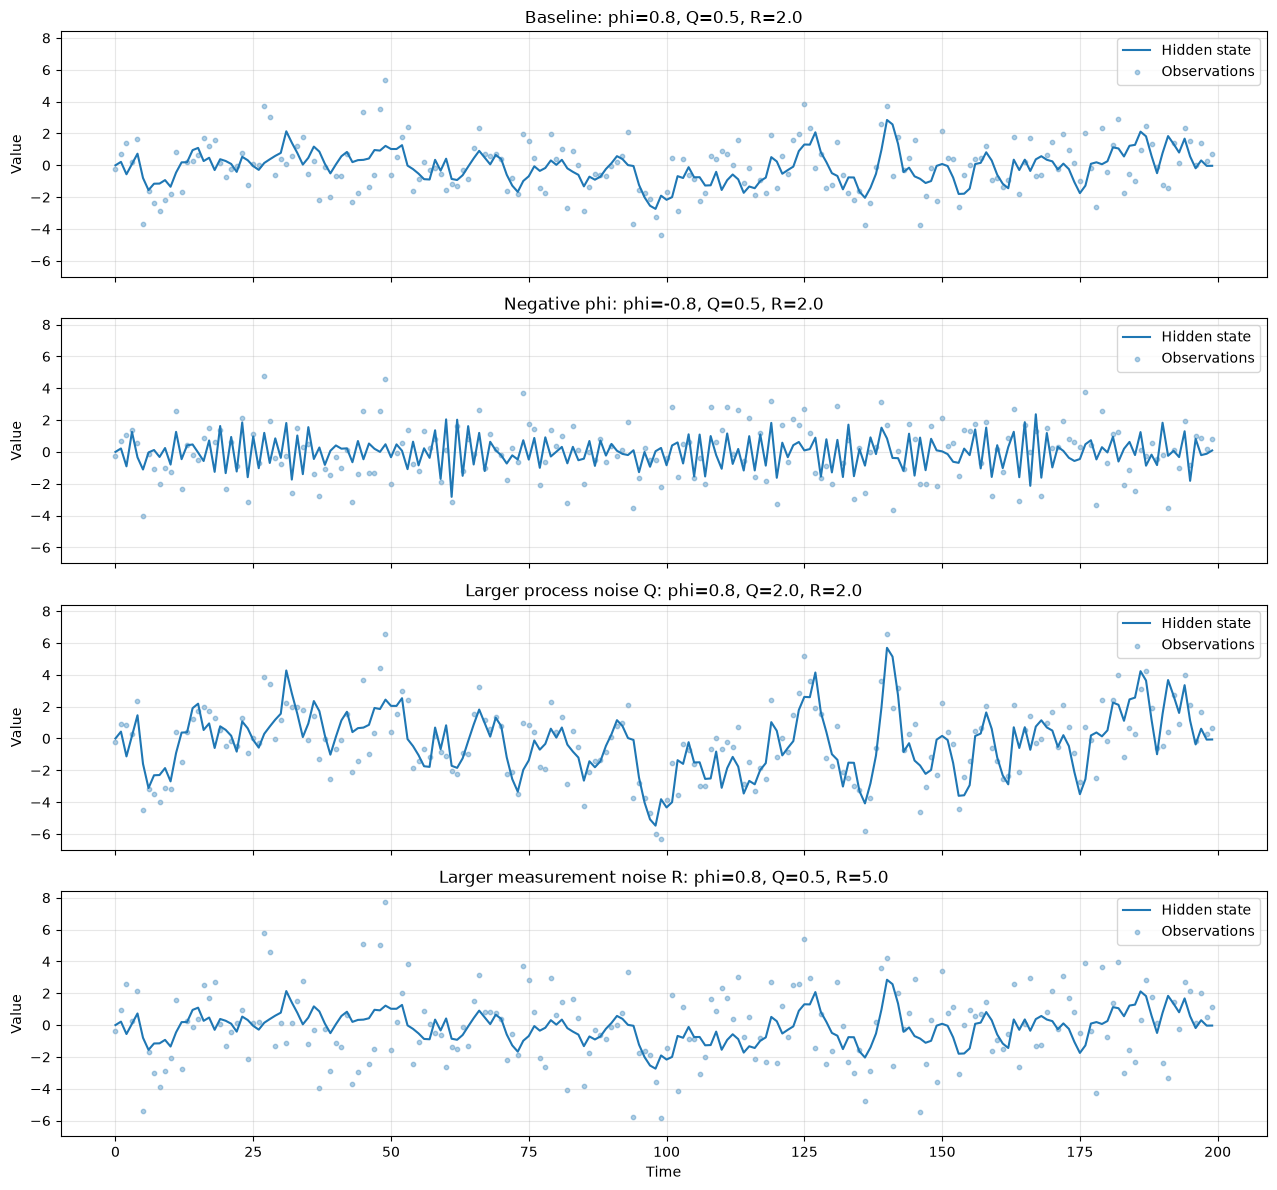

                                phi       Q       R  State std (simulated)  Measurement RMSE  Stationary state variance
Scenario                                                                                                               
Baseline                    0.80000 0.50000 2.00000                0.96907           1.43683                    1.38889
Negative phi               -0.80000 0.50000 2.00000                0.96408           1.43683                    1.38889
Larger process noise Q      0.80000 2.00000 2.00000                1.93815           1.43683                    5.55556
Larger measurement noise R  0.80000 0.50000 5.00000                0.96907           2.27184                    1.38889


In [8]:
def simulate_state_model(phi, Q, R, n=200, seed=42):
    local_rng = np.random.default_rng(seed)
    state_noise = local_rng.normal(size=n - 1)
    measurement_noise = local_rng.normal(size=n)
    latent = np.zeros(n)
    for t in range(1, n):
        latent[t] = phi * latent[t - 1] + np.sqrt(Q) * state_noise[t - 1]
    measured = latent + np.sqrt(R) * measurement_noise
    return latent, measured


state_scenarios = [
    ('Baseline', 0.8, 0.5, 2.0),
    ('Negative phi', -0.8, 0.5, 2.0),
    ('Larger process noise Q', 0.8, 2.0, 2.0),
    ('Larger measurement noise R', 0.8, 0.5, 5.0),
]
state_metrics, state_simulations = [], {}
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True, sharey=True)
for ax, (label, scenario_phi, scenario_Q, scenario_R) in zip(axes, state_scenarios):
    latent, measured = simulate_state_model(scenario_phi, scenario_Q, scenario_R)
    state_simulations[label] = (latent, measured)
    state_metrics.append({'Scenario': label, 'phi': scenario_phi, 'Q': scenario_Q, 'R': scenario_R,
                          'State std (simulated)': latent.std(ddof=1),
                          'Measurement RMSE': np.sqrt(np.mean((measured - latent) ** 2)),
                          'Stationary state variance': scenario_Q / (1 - scenario_phi ** 2)})
    ax.plot(latent, linewidth=1.5, label='Hidden state')
    ax.scatter(range(len(measured)), measured, alpha=0.35, s=10, label='Observations')
    ax.set_title(f'{label}: phi={scenario_phi}, Q={scenario_Q}, R={scenario_R}')
    ax.set_ylabel('Value')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Time')
fig.tight_layout()
plt.show()
state_comparison = pd.DataFrame(state_metrics).set_index('Scenario')
print(state_comparison.to_string(float_format=lambda value: f'{value:.5f}'))

### Exercise 5 — interpretation

- The missing recurrence is `state[t] = phi * state[t-1] + w_t`. The state starts at zero; this initial value is fixed rather than drawn from the stationary distribution.
- With phi = 0.8, state deviations persist with the same sign. With phi = -0.8, deviations tend to alternate signs. Both have absolute phi below one and the same theoretical long-run variance `Q / (1 - phi**2)`; the sign changes the autocorrelation pattern.
- Increasing Q from 0.5 to 2.0 doubles the process-noise standard deviation and multiplies the theoretical stationary state variance by four. Actual hidden-state fluctuations become larger.
- Increasing R from 2.0 to 5.0 increases measurement scatter around the same hidden state. It does not change the state equation or its latent trajectory when the same random innovations are reused.
- Every scenario changes exactly one parameter relative to baseline and starts with the same random seed, giving matched standard-normal innovations. The measurement RMSE estimates sqrt(R) with finite-sample variation. These are simulations of a known state, not estimates obtained by filtering real observations.

## BONUS: 2 Body
1. Analyzuje dáta v súboroch energy.csv, Precious_Metals.csv, Technology.csv a na základe výsledkov rozhodnite, pre ktoré datasety je vhodný VAR a pre ktoré VECM. Aký kointegračný rank bol určený a čo to znamená?
2. Iba pre dataset, pre ktorý je vhodný VECM, vyberte počet lagov pomocou AIC, odhadnite VECM s určeným kointegračným rankom a vykonajte rolling-origin predikciu s horizontom 1 pozorovanie dopredu. Prečo vstupné dáta pre VECM sú premenné v ich pôvodných úrovniach namiesto ich prvých diferencií?
    - dáta nezabudnite rozdeliť a predikciu vykonajte na posledných troch mesiacoch
3. Porovnajte skutočné a predikované hodnoty na grafe a vypočítajte MAE a RMSE.

### Bonus — training diagnostics and sensitivity of the rank

Analyze the original supplied CSVs independently of the ETF variables. For each dataset, reserve its own last three calendar months. Use ADF on training levels and differences, then select lagged differences by AIC over 0–10 using a VECM/VAR representation with an unrestricted constant (`deterministic='co'`). Apply Johansen on training levels at that selected lag, with `det_order=0`.

Report both the usual **5%** trace-test decision and a **1% sensitivity analysis**. Full rank is not the reduced-rank I(1) situation for which a cointegrated VECM is motivated. If ADF suggests I(1) but Johansen gives full rank, report the disagreement instead of forcing a rank between zero and k. The subsequent reduced-rank VECM exercise is explicitly conditional on the 1% specification; it is not a claim that 5% tests selected that model.

In [9]:
bonus_datasets = {}
bonus_analysis = {}
bonus_decision_rows, bonus_rank_sensitivity_rows = [], []
for name in ['energy', 'Precious_Metals', 'Technology']:
    panel = validate_panel(pd.read_csv(data_dir / f'{name}.csv', index_col='Date', parse_dates=['Date']))
    training, testing = split_last_three_months(panel)
    adf = adf_table(training)
    # Scaling uses training statistics only; input observations remain in levels.
    scale = training.std()
    selection = select_vecm_order((training / scale).to_numpy(), maxlags=10, deterministic='co')
    diff_lags = int(selection.aic)
    trace = johansen_table(training, k_ar_diff=diff_lags)
    rank_5 = sequential_rank(trace, 0.05)
    rank_1 = sequential_rank(trace, 0.01)
    choice_5 = model_recommendation(adf, rank_5, panel.shape[1], 0.05)
    choice_1 = model_recommendation(adf, rank_1, panel.shape[1], 0.01)
    bonus_datasets[name] = panel
    bonus_analysis[name] = {'train': training, 'test': testing, 'adf': adf, 'trace': trace,
                             'scale': scale, 'selection': selection, 'diff_lags': diff_lags,
                             'rank_5': rank_5, 'rank_1': rank_1,
                             'choice_5': choice_5, 'choice_1': choice_1}
    bonus_decision_rows.append({'Dataset': name, 'Train': len(training), 'Test': len(testing),
                                'AIC diff lags': diff_lags, 'Rank (5%)': rank_5,
                                'Decision (5%)': choice_5, 'Rank (1%)': rank_1,
                                'Decision (1%)': choice_1})
    print(f'\n{name}: training {training.index.min():%Y-%m-%d} to {training.index.max():%Y-%m-%d}; '
          f'test {testing.index.min():%Y-%m-%d} to {testing.index.max():%Y-%m-%d}')
    print(adf.to_string(float_format=lambda value: f'{value:.6g}'))
    print(selection.summary())
    print(trace.to_string(index=False, float_format=lambda value: f'{value:.6g}'))
    # A small, prespecified diagnostic grid shows sensitivity, not a search for a desired rank.
    for candidate_lag in sorted({1, diff_lags, 6, 10}):
        candidate_trace = johansen_table(training, k_ar_diff=candidate_lag)
        bonus_rank_sensitivity_rows.append({'Dataset': name, 'Difference lags': candidate_lag,
                                            'Rank (5%)': sequential_rank(candidate_trace, 0.05),
                                            'Rank (1%)': sequential_rank(candidate_trace, 0.01)})

bonus_decisions = pd.DataFrame(bonus_decision_rows).set_index('Dataset')
bonus_rank_sensitivity = pd.DataFrame(bonus_rank_sensitivity_rows).set_index(['Dataset', 'Difference lags'])
print('\nTraining-only model decisions:')
print(bonus_decisions.to_string())
print('\nRank sensitivity (diagnostic only; AIC choice is not changed):')
print(bonus_rank_sensitivity.to_string())


energy: training 2024-01-01 to 2025-09-30; test 2025-10-01 to 2025-12-31
                             ADF statistic     p-value  ADF lags  Observations  Reject unit root
Variable   Transformation                                                                       
Biomass    Level                  -2.05276    0.263931         8           630             False
           First difference       -11.5047 4.40533e-21         7           630              True
Geothermal Level                  -1.80467    0.378143        10           628             False
           First difference       -11.1027  3.8291e-20         9           628              True
 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -5.431     -5.375*    0.004377      -5.409
1       -5.426      -5.341    0.004400      -5.393
2       -5.457      -5.344    0.004265     -5.413*
3       -5.457      -5.315    0.004267

### Bonus — one-observation-ahead VECM forecasts

For datasets classified as VECM in the **1% sensitivity analysis**, keep the training-selected AIC lag count and rank fixed. Refit coefficients on expanding histories of **levels** and forecast one observation. The test observations never influence the initial rank, selected lag, or scale. Report the complete selection table above so that this conditional evaluation remains distinguishable from the 5% model decision.


energy: conditional VECM rank=1, difference lags=4, level VAR order=5, alpha=0.01
Cointegrating vectors for scaled levels (beta):
            Relation 1
Biomass       1.000000
Geothermal   -1.023336
Adjustment coefficients (alpha):
            Relation 1
Biomass      -0.072415
Geothermal    0.046795
Errors on the original CSV scale (separate units for each variable):
                                      Dataset       MAE      RMSE
Model                      Variable                              
VECM (1% rank sensitivity) Biomass     energy 61.661521 82.465836
                           Geothermal  energy  0.759845  0.971523
Naive                      Biomass     energy 63.880840 85.011624
                           Geothermal  energy  0.746721  0.978791
              History end  Training observations  Rank  Difference lags
Forecast date                                                          
2025-10-01     2025-09-30                    639     1                4
2025-12-31     20

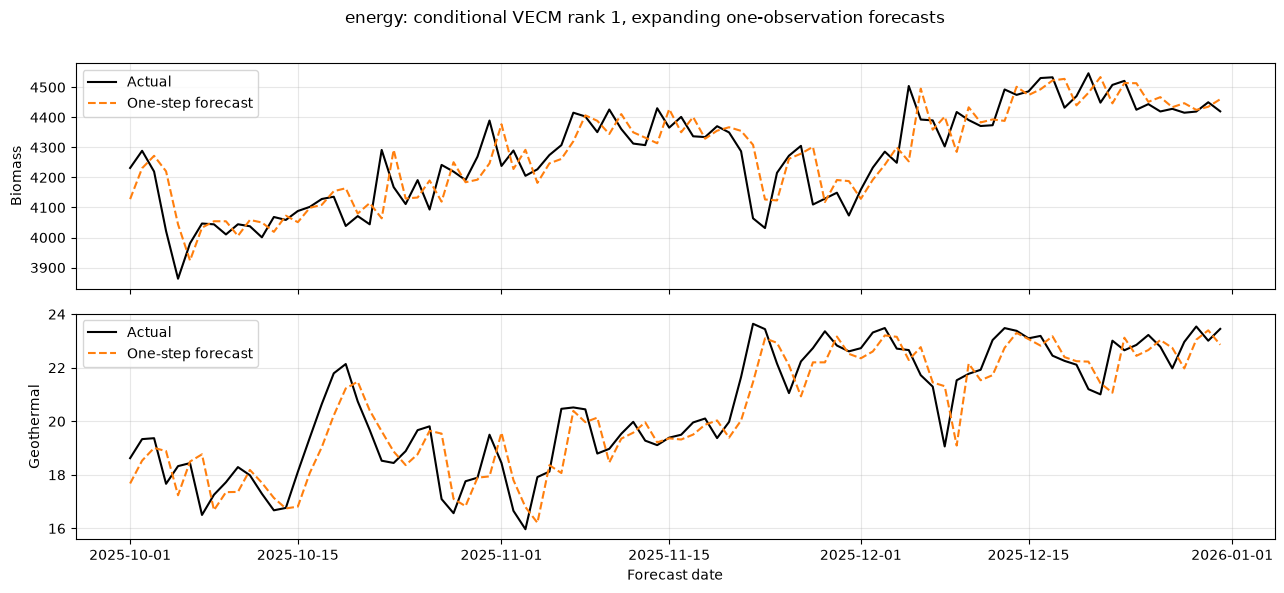

Precious_Metals: no reduced-rank VECM evaluation (VAR in first differences at 1%).
Technology: no reduced-rank VECM evaluation (VAR in first differences at 1%).


In [10]:
bonus_predictions, bonus_origins, bonus_fits, bonus_score_tables = {}, {}, {}, []
for name, analysis in bonus_analysis.items():
    if analysis['choice_1'] != 'VECM':
        print(f"{name}: no reduced-rank VECM evaluation ({analysis['choice_1']} at 1%).")
        continue
    training, testing = analysis['train'], analysis['test']
    scale = analysis['scale']
    rank, diff_lags = analysis['rank_1'], analysis['diff_lags']
    fitted_training = VECM((training / scale).to_numpy(), k_ar_diff=diff_lags,
                           coint_rank=rank, deterministic='co').fit()
    bonus_fits[name] = fitted_training
    print(f'\n{name}: conditional VECM rank={rank}, difference lags={diff_lags}, '
          f'level VAR order={diff_lags + 1}, alpha=0.01')
    print('Cointegrating vectors for scaled levels (beta):')
    print(pd.DataFrame(fitted_training.beta, index=training.columns,
                       columns=[f'Relation {j + 1}' for j in range(rank)]).to_string())
    print('Adjustment coefficients (alpha):')
    print(pd.DataFrame(fitted_training.alpha, index=training.columns,
                       columns=[f'Relation {j + 1}' for j in range(rank)]).to_string())
    history = training.copy()
    rows, audit_rows = [], []
    for forecast_date, actual_row in testing.iterrows():
        if history.index.max() >= forecast_date:
            raise ValueError('VECM history includes the target or future data.')
        fit = VECM((history / scale).to_numpy(), k_ar_diff=diff_lags,
                   coint_rank=rank, deterministic='co').fit()
        # VECM.predict returns levels on the supplied scale, not differences.
        prediction = np.asarray(fit.predict(steps=1))[0] * scale.to_numpy()
        rows.append(prediction)
        audit_rows.append({'Forecast date': forecast_date, 'History end': history.index.max(),
                            'Training observations': len(history), 'Rank': rank,
                            'Difference lags': diff_lags})
        history.loc[forecast_date] = actual_row
    predicted = pd.DataFrame(rows, index=testing.index, columns=testing.columns)
    bonus_predictions[name] = predicted
    bonus_origins[name] = pd.DataFrame(audit_rows).set_index('Forecast date')
    score = forecast_scores(testing, predicted)
    naive = bonus_datasets[name].shift(1).loc[testing.index]
    naive_score = forecast_scores(testing, naive)
    comparison = pd.concat({'VECM (1% rank sensitivity)': score, 'Naive': naive_score}, names=['Model'])
    comparison.insert(0, 'Dataset', name)
    bonus_score_tables.append(comparison)
    print('Errors on the original CSV scale (separate units for each variable):')
    print(comparison.to_string(float_format=lambda value: f'{value:.6f}'))
    print(bonus_origins[name].iloc[[0, -1]].to_string())
    plot_predictions(testing, predicted,
                     f'{name}: conditional VECM rank {rank}, expanding one-observation forecasts')

if bonus_score_tables:
    bonus_scores = pd.concat(bonus_score_tables)
else:
    bonus_scores = pd.DataFrame()
    print('No dataset meets the stated I(1), reduced-rank VECM criteria at 1%; no model is forced.')

### Bonus — interpretation

- The decisions are computed from the **supplied files**, not from assumptions about the names of the datasets. Each dataset has its own test endpoint: energy covers 2024–2025, while the stock/metal CSVs cover 2017–2023. Do not use the ETF exercise's 2026 split for these files.
- **Rank meaning:** r=0 supplies no detected error-correction relation. For 0<r<k, there are r stationary combinations and k-r common stochastic trends. A full-rank result is not evidence for the usual reduced-rank I(1) VECM; when it conflicts with ADF, inspect the deterministic specification, lag adequacy, structural changes, and test power.
- The 5% and 1% columns, together with the lag sensitivity table, show that rank is an estimated, specification-dependent quantity. The AIC-selected lag is retained; the diagnostic grid is not used to select a more convenient rank. A conditional 1% VECM forecast does not resolve a disagreement between tests or establish that it is the uniquely correct model.
- In a VECM, `Delta y[t] = alpha @ beta.T @ y[t-1] + sum(Gamma[i] @ Delta y[t-i]) + constant + error`. The lagged **levels** supply the equilibrium error `beta.T @ y[t-1]`. Passing only first differences would remove this information and effectively difference the input again.
- Dividing levels by training standard deviations is a fixed invertible change of units, not differencing. Forecasts are multiplied by the same scales to recover original units. VECM's prediction already returns levels, so no previous price is added again.
- One step means the next observed row: the next calendar day for energy and the next shared trading date for equities. Forecasts are compared with the same-date observations using MAE/RMSE separately for each variable. Values from variables in different units should not be pooled into a single unscaled error.
- Naive is included as a benchmark. A visible fit or detected cointegration does not guarantee improvement over predicting the last observed level. These results describe one holdout period and should not be used to retune the reported pipeline without a further untouched evaluation period.

**Results for the supplied CSVs:** Precious_Metals and Technology both have rank **0** at their training-selected AIC lags (2 and 9 lagged differences), so VAR in first differences is supported. For energy, AIC selects **4** lagged differences. The trace statistic for `r <= 1` is **4.441**, above the 5% critical value **3.8415**, but below the 1% critical value **6.6349**. Thus the 5% rank is **2** (full rank, conflicting with the ADF I(1) indication), while the 1% rank is **1**. No dataset is unambiguously selected for reduced-rank VECM by the baseline 5% procedure. The energy forecast below is the explicitly conditional 1% sensitivity example, not a replacement of that conclusion.

The conditional energy VECM uses rank 1, four lagged differences (level VAR order 5), and 92 one-day forecasts for October–December 2025:

| Variable | VECM MAE | VECM RMSE | Naive MAE | Naive RMSE |
| --- | ---: | ---: | ---: | ---: |
| Biomass | 61.661521 | 82.465836 | 63.880840 | 85.011624 |
| Geothermal | 0.759845 | 0.971523 | 0.746721 | 0.978791 |

VECM has slightly lower RMSE for both variables. For Geothermal, Naive has lower MAE, so the methods are not uniformly ranked across error measures. Scores retain each column's original CSV units.

### API references

- [yfinance.download: adjustment and exclusive end date](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html)
- [statsmodels: vector autoregressions and cointegration](https://www.statsmodels.org/stable/vector_ar.html)
- [VECM lag selection](https://www.statsmodels.org/stable/generated/statsmodels.tsa.vector_ar.vecm.select_order.html) and [VECM specification](https://www.statsmodels.org/stable/generated/statsmodels.tsa.vector_ar.vecm.VECM.html)